# Molecular Property Prediction with Graph Neural Networks

Blood–brain barrier penetration on the MoleculeNet BBBP dataset.

Analysis, figures and discussion: `report/main.pdf`. Setup and run order: `README.md`.


In [1]:
!pip -q install torch-geometric rdkit scikit-learn

## Part A

In [12]:
import torch
from torch_geometric.data import Data
import pandas as pd
import numpy as np

In [13]:
from pathlib import Path
from torch_geometric.datasets import MoleculeNet
DATA_ROOT = Path("data/MoleculeNet")
dataset = MoleculeNet(
root=str(DATA_ROOT),
name="BBBP"
)
print(dataset)
print("Number of molecules:", len(dataset))
print("First graph:", dataset[0])

BBBP(2039)
Number of molecules: 2039
First graph: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])


In [14]:
graph = dataset[0]
print("Node-feature shape:", graph.x.shape)
print("Edge-index shape:", graph.edge_index.shape)
print("Edge-feature shape:", graph.edge_attr.shape)
print("Label:", graph.y)
print("SMILES:", graph.smiles)

Node-feature shape: torch.Size([20, 9])
Edge-index shape: torch.Size([2, 40])
Edge-feature shape: torch.Size([40, 3])
Label: tensor([[1.]])
SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


In [15]:
r = []
for i, g in enumerate(dataset):
    r.append({
        "idx": i,
        "smiles": g.smiles,
        "x": g.x,
        "edge_index": g.edge_index,
        "edge_attr": g.edge_attr,
        "y": g.y.view(-1)[0].item() if g.y is not None else None
    })
df = pd.DataFrame(r)

In [17]:
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")

df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
df["canonical"] = df["mol"].apply(lambda m: Chem.MolToSmiles(m) if m is not None else None)

counts = df["y"].value_counts().sort_index()
sizes = df.groupby("canonical").size()
dups = sizes[sizes > 1]
labels_per_mol = df[df["canonical"].isin(dups.index)].groupby("canonical")["y"].nunique()

print(f"Length: {len(df)}")
print(f"Non-finite labels: {(~np.isfinite(df['y'].astype(float))).sum()}")
print(f"Invalid molecules: {df['canonical'].isna().sum()}")
print(f"Empty graphs: {(df['x'].apply(len) == 0).sum()}")
print(f"Class counts: {counts.to_dict()}")
print(f"Class proportions: {(counts / len(df)).round(4).to_dict()}")
print(f"Unique raw / canonical SMILES: {df['smiles'].nunique()} / {df['canonical'].nunique()}")
print(f"Duplicate molecules: {len(dups)} ({dups.sum()} records, {dups.sum() - len(dups)} redundant)")
print(f"Consistent / conflicting labels: {(labels_per_mol == 1).sum()} / {(labels_per_mol > 1).sum()}")
print(f"Conflicting: {labels_per_mol[labels_per_mol > 1].index.tolist()}")

Length: 2039
Non-finite labels: 0
Invalid molecules: 0
Empty graphs: 0
Class counts: {0.0: 479, 1.0: 1560}
Class proportions: {0.0: 0.2349, 1.0: 0.7651}
Unique raw / canonical SMILES: 2039 / 1975
Duplicate molecules: 60 (124 records, 64 redundant)
Consistent / conflicting labels: 50 / 10
Conflicting: ['CC(=O)Oc1ccccc1C(=O)O', 'CCOC(=O)N1CCC(=C2c3ccc(Cl)cc3CCc3cccnc32)CC1', 'CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1', 'CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2', 'COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC', 'COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1', 'C[C@H]1C[C@@H]2[C@H]([C@@H](O)C[C@@]3(C)[C@H]2CC[C@]3(O)C(=O)CO)[C@@]2(C)C=CC(=O)C=C12', 'Clc1ccc(COC(Cn2ccnc2)c2ccc(Cl)cc2Cl)c(Cl)c1', 'N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O', 'c1ccc2c(c1)Sc1ccccc1N2CC1CN2CCC1CC2']


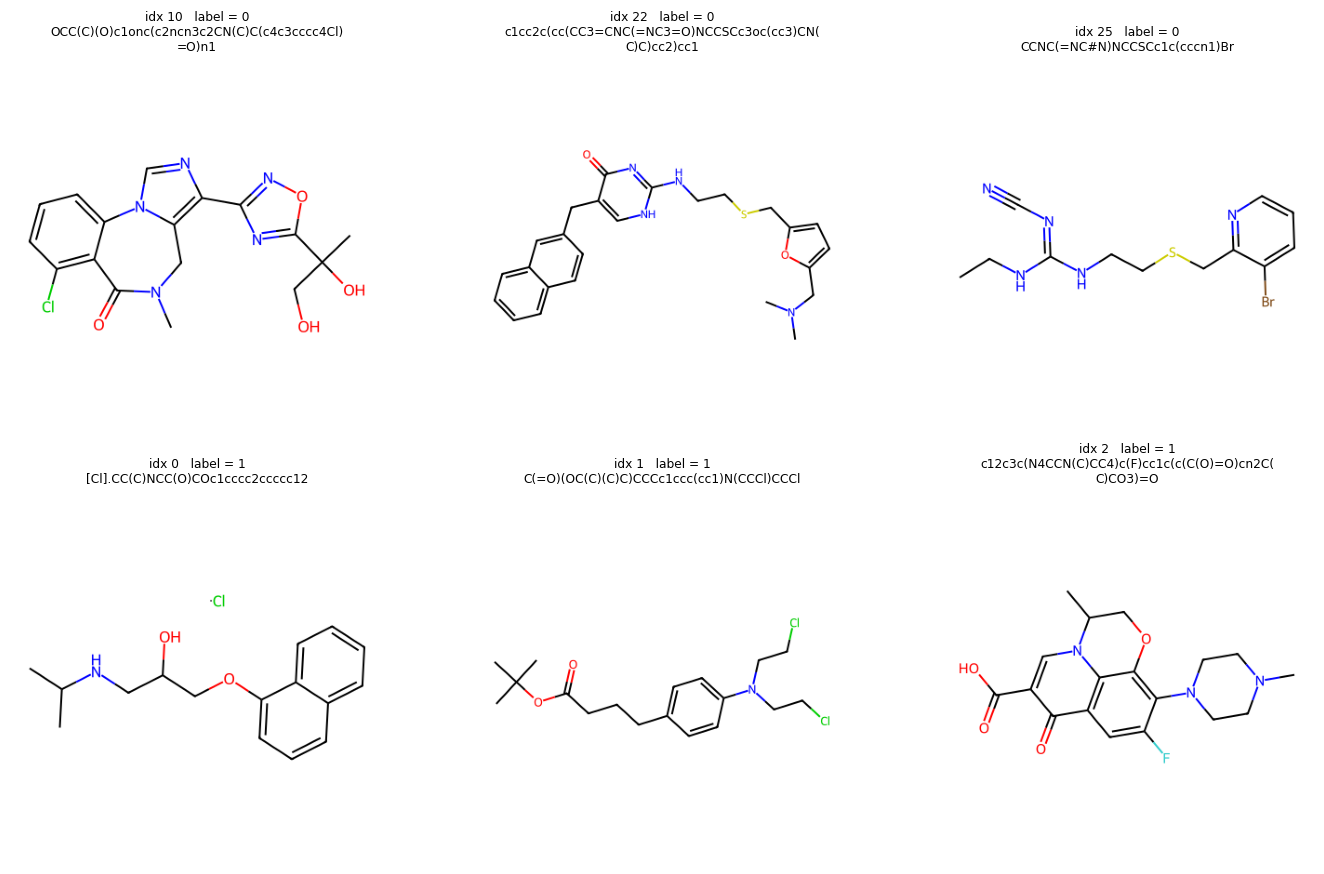

In [18]:
import textwrap
import matplotlib.pyplot as plt
from rdkit.Chem import Draw

sample = pd.concat([df[df["y"] == 0].head(3), df[df["y"] == 1].head(3)])

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, r in zip(axes.flat, sample.itertuples()):
    ax.imshow(Draw.MolToImage(r.mol, size=(400, 400)))
    ax.set_title(
        f"idx {r.idx}   label = {int(r.y)}\n" + "\n".join(textwrap.wrap(r.smiles, 42)),
        fontsize=8,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

         atoms    bonds
count  2039.00  2039.00
mean     24.06    25.95
std      10.59    11.72
min       2.00     1.00
25%      18.00    19.00
50%      23.00    25.00
75%      28.50    31.00
max     132.00   145.00


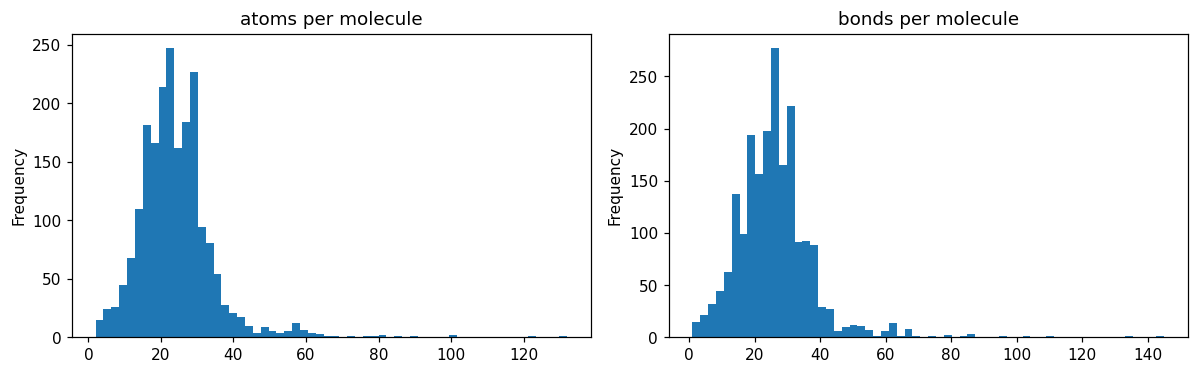

x.shape: (20, 9)
edge_index.shape: (2, 40)
edge_attr.shape: (40, 3)
y: tensor([[1.]])
smiles: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


In [19]:
df["atoms"] = df["x"].apply(len)
df["bonds"] = df["edge_index"].apply(lambda e: e.shape[1] // 2)

print(df[["atoms", "bonds"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["atoms"].plot.hist(bins=60, ax=axes[0], title="atoms per molecule")
df["bonds"].plot.hist(bins=60, ax=axes[1], title="bonds per molecule")
plt.tight_layout()
plt.show()

g = dataset[0]
print(f"x.shape: {tuple(g.x.shape)}")
print(f"edge_index.shape: {tuple(g.edge_index.shape)}")
print(f"edge_attr.shape: {tuple(g.edge_attr.shape)}")
print(f"y: {g.y}")
print(f"smiles: {g.smiles}")

## Part B

In [20]:
from torch_geometric.utils.smiles import x_map, e_map

X = torch.cat([g.x for g in dataset])
E = torch.cat([g.edge_attr for g in dataset])

def summarize(col, name, vals):
    seen = col.unique().tolist()
    decoded = [str(vals[c]) for c in seen]
    shown = ", ".join(decoded[:7]) + (", ..." if len(decoded) > 7 else "")
    print(f"  col {name:22s} {len(vals):3d} categories   observed ({len(seen)}): {shown}")

print(f"x: {tuple(X.shape)} = (atoms, 9 categorical columns), dtype {X.dtype}")
for i, (name, vals) in enumerate(x_map.items()):
    summarize(X[:, i], f"{i} {name}", vals)

print(f"\nedge_attr: {tuple(E.shape)} = (directed edges, 3 categorical columns), dtype {E.dtype}")
for i, (name, vals) in enumerate(e_map.items()):
    summarize(E[:, i], f"{i} {name}", vals)

print(f"\nformal_charge code 5 decodes to {x_map['formal_charge'][5]}, code 7 to {x_map['formal_charge'][7]}")
print(f"hybridization code 3 decodes to {x_map['hybridization'][3]}, code 4 to {x_map['hybridization'][4]}")

g = dataset[0]
print(f"\nedge_index: {tuple(g.edge_index.shape)} = (2, directed edges), dtype {g.edge_index.dtype}")
print(f"columns 0 and 1 are the same bond twice: {g.edge_index[:, 0].tolist()} and {g.edge_index[:, 1].tolist()}")
print(f"edge_attr rows 0 and 1 therefore match: {g.edge_attr[0].tolist()} and {g.edge_attr[1].tolist()}")

x: (49068, 9) = (atoms, 9 categorical columns), dtype torch.int64
  col 0 atomic_num           119 categories   observed (13): 1, 5, 6, 7, 8, 9, 11, ...
  col 1 chirality              9 categories   observed (3): CHI_UNSPECIFIED, CHI_TETRAHEDRAL_CW, CHI_TETRAHEDRAL_CCW
  col 2 degree                11 categories   observed (5): 0, 1, 2, 3, 4
  col 3 formal_charge         12 categories   observed (4): -1, 0, 1, 2
  col 4 num_hs                 9 categories   observed (4): 0, 1, 2, 3
  col 5 num_radical_electrons   5 categories   observed (2): 0, 1
  col 6 hybridization          8 categories   observed (4): S, SP, SP2, SP3
  col 7 is_aromatic            2 categories   observed (2): False, True
  col 8 is_in_ring             2 categories   observed (2): False, True

edge_attr: (105842, 3) = (directed edges, 3 categorical columns), dtype torch.int64
  col 0 bond_type             22 categories   observed (4): SINGLE, DOUBLE, TRIPLE, AROMATIC
  col 1 stereo                 6 categories   obs

In [21]:
import torch.nn as nn

class AtomEncoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.emb = nn.ModuleList([nn.Embedding(len(v), dim) for v in x_map.values()])

    def forward(self, x):
        return sum(e(x[:, i]) for i, e in enumerate(self.emb))

class BondEncoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.emb = nn.ModuleList([nn.Embedding(len(v), dim) for v in e_map.values()])

    def forward(self, edge_attr):
        return sum(e(edge_attr[:, i]) for i, e in enumerate(self.emb))

HIDDEN = 64
atom_encoder = AtomEncoder(HIDDEN)
bond_encoder = BondEncoder(HIDDEN)

g = dataset[0]
print("encoding: trainable nn.Embedding per categorical column, summed over columns")
print(f"x          {tuple(g.x.shape)} -> {tuple(atom_encoder(g.x).shape)}")
print(f"edge_attr  {tuple(g.edge_attr.shape)} -> {tuple(bond_encoder(g.edge_attr).shape)}")
print(f"atom embedding parameters: {sum(p.numel() for p in atom_encoder.parameters()):,}")
print(f"bond embedding parameters: {sum(p.numel() for p in bond_encoder.parameters()):,}")
print(f"one-hot width would be {sum(len(v) for v in x_map.values())} for atoms and {sum(len(v) for v in e_map.values())} for bonds")

encoding: trainable nn.Embedding per categorical column, summed over columns
x          (20, 9) -> (20, 64)
edge_attr  (40, 3) -> (40, 64)
atom embedding parameters: 11,328
bond embedding parameters: 1,920
one-hot width would be 177 for atoms and 30 for bonds


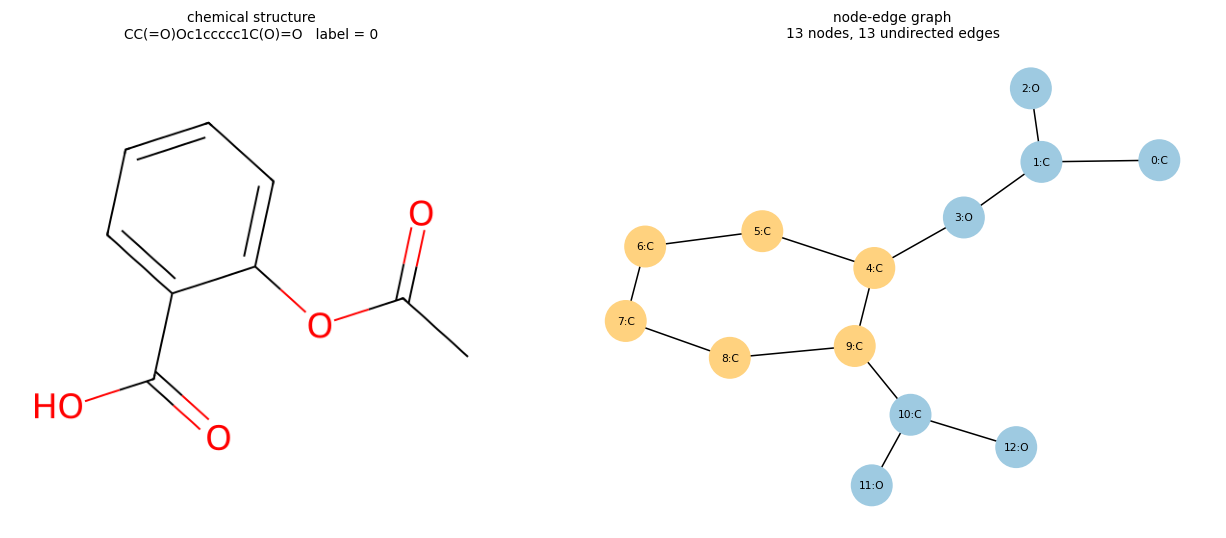

atoms 13 == nodes 13, bonds 13 == edges 13
atomic numbers from RDKit match x[:, 0]: True
bond 0-1 SINGLE   -> edge_index[:, 0] = [0, 1], edge_attr = ['SINGLE', 'STEREONONE', False]
bond 1-2 DOUBLE   -> edge_index[:, 2] = [1, 2], edge_attr = ['DOUBLE', 'STEREONONE', True]
bond 1-3 SINGLE   -> edge_index[:, 3] = [1, 3], edge_attr = ['SINGLE', 'STEREONONE', True]
bond 3-4 SINGLE   -> edge_index[:, 6] = [3, 4], edge_attr = ['SINGLE', 'STEREONONE', True]


In [22]:
import networkx as nx
from torch_geometric.utils import to_networkx

i = 98
g, mol = dataset[i], df.loc[i, "mol"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(Draw.MolToImage(mol, size=(500, 500)))
axes[0].set_title(f"chemical structure\n{g.smiles}   label = {int(df.loc[i, 'y'])}", fontsize=9)
axes[0].axis("off")

nxg = to_networkx(g, to_undirected=True)
pos = nx.kamada_kawai_layout(nxg)
labels = {a.GetIdx(): f"{a.GetIdx()}:{a.GetSymbol()}" for a in mol.GetAtoms()}
colors = ["#ffd27f" if a.GetIsAromatic() else "#9ecae1" for a in mol.GetAtoms()]
nx.draw(nxg, pos, ax=axes[1], labels=labels, node_color=colors, node_size=700, font_size=7)
axes[1].set_title(f"node-edge graph\n{g.num_nodes} nodes, {g.num_edges // 2} undirected edges", fontsize=9)
plt.tight_layout()
plt.show()

print(f"atoms {mol.GetNumAtoms()} == nodes {g.num_nodes}, bonds {mol.GetNumBonds()} == edges {g.num_edges // 2}")
print(f"atomic numbers from RDKit match x[:, 0]: {[a.GetAtomicNum() for a in mol.GetAtoms()] == g.x[:, 0].tolist()}")
for b in list(mol.GetBonds())[:4]:
    u, v = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
    k = ((g.edge_index[0] == u) & (g.edge_index[1] == v)).nonzero()[0, 0]
    print(f"bond {u}-{v} {str(b.GetBondType()):8s} -> edge_index[:, {k}] = {g.edge_index[:, k].tolist()}, "
          f"edge_attr = {[e_map[n][c] for n, c in zip(e_map, g.edge_attr[k].tolist())]}")

In [23]:
from torch_geometric.loader import DataLoader

loader = DataLoader(dataset, batch_size=32, shuffle=False)
batch = next(iter(loader))

print(batch)
print(f"x          {tuple(batch.x.shape)}   all atoms of the {batch.num_graphs} graphs stacked, 9 feature columns")
print(f"edge_index {tuple(batch.edge_index.shape)}  node ids re-indexed into the stacked graph, no cross-graph edges")
print(f"edge_attr  {tuple(batch.edge_attr.shape)}   one row per directed edge, 3 feature columns")
print(f"batch      {tuple(batch.batch.shape)}      graph id per atom, values {batch.batch.min().item()}..{batch.batch.max().item()}")
print(f"y          {tuple(batch.y.shape)}      one label per graph")
print(f"atoms per graph: {torch.bincount(batch.batch).tolist()}")
print(f"offset check: graph 1 starts at atom {int((batch.batch == 1).nonzero()[0, 0])} = atoms in graph 0")

DataBatch(x=[778, 9], edge_index=[2, 1664], edge_attr=[1664, 3], smiles=[32], y=[32, 1], batch=[778], ptr=[33])
x          (778, 9)   all atoms of the 32 graphs stacked, 9 feature columns
edge_index (2, 1664)  node ids re-indexed into the stacked graph, no cross-graph edges
edge_attr  (1664, 3)   one row per directed edge, 3 feature columns
batch      (778,)      graph id per atom, values 0..31
y          (32, 1)      one label per graph
atoms per graph: [20, 23, 26, 21, 29, 44, 38, 22, 29, 15, 27, 17, 3, 49, 23, 30, 34, 21, 33, 16, 6, 10, 32, 22, 27, 19, 23, 23, 17, 37, 16, 26]
offset check: graph 1 starts at atom 20 = atoms in graph 0


In [24]:
loader = DataLoader(dataset, batch_size=64, shuffle=False)

finite, nonempty, aligned, graphs, atoms = True, True, True, 0, 0
for batch in loader:
    finite &= bool(torch.isfinite(batch.y).all())
    nonempty &= bool((torch.bincount(batch.batch, minlength=batch.num_graphs) > 0).all())
    aligned &= batch.y.view(-1).numel() == batch.num_graphs
    graphs += batch.num_graphs
    atoms += batch.num_nodes

print(f"labels finite: {finite}")
print(f"every graph has at least one atom: {nonempty}")
print(f"labels per batch == graphs per batch: {aligned}")
print(f"graphs after batching: {graphs} / {len(dataset)} -> {graphs == len(dataset)}")
print(f"atoms after batching: {atoms} / {int(df['atoms'].sum())} -> {atoms == int(df['atoms'].sum())}")

labels finite: True
every graph has at least one atom: True
labels per batch == graphs per batch: True
graphs after batching: 2039 / 2039 -> True
atoms after batching: 49068 / 49068 -> True


## Part C

In [25]:
from rdkit.Chem.Scaffolds import MurckoScaffold

conflicting = labels_per_mol[labels_per_mol > 1].index
data = df[~df["canonical"].isin(conflicting)].drop_duplicates("canonical").reset_index(drop=True)
data["scaffold"] = data["mol"].apply(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False))

print(f"records in dataset: {len(df)}")
print(f"dropped as conflicting duplicates: {int(df['canonical'].isin(conflicting).sum())}")
print(f"dropped as redundant copies: {len(df) - int(df['canonical'].isin(conflicting).sum()) - len(data)}")
print(f"modelling set: {len(data)} unique molecules")
print(f"positive proportion: {data['y'].mean():.4f}")
print(f"unique scaffolds: {data['scaffold'].nunique()}")
print(f"acyclic molecules (empty scaffold): {int((data['scaffold'] == '').sum())}")
print(f"largest scaffold groups: {data['scaffold'].value_counts().head(3).to_dict()}")

records in dataset: 2039
dropped as conflicting duplicates: 20
dropped as redundant copies: 54
modelling set: 1965 unique molecules
positive proportion: 0.7634
unique scaffolds: 1020
acyclic molecules (empty scaffold): 95
largest scaffold groups: {'c1ccccc1': 128, '': 95, 'O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21': 74}


In [26]:
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
n_train, n_val = int(0.70 * len(data)), int(0.15 * len(data))

pos = np.arange(len(data))
tr, rest = train_test_split(pos, train_size=0.70, stratify=data["y"], random_state=SEED)
va, te = train_test_split(rest, train_size=0.5, stratify=data.loc[rest, "y"], random_state=SEED)
random_split = {"train": np.sort(tr), "val": np.sort(va), "test": np.sort(te)}

print("positive rate by position in the original file:")
for lo in range(0, len(data), 250):
    blk = data.iloc[lo:lo + 250]
    print(f"  rows {lo:4d}-{min(lo + 249, len(data) - 1):4d}  n={len(blk):3d}  positive rate = {blk['y'].mean():.3f}")

groups = list(data.groupby("scaffold").indices.values())
rng.shuffle(groups)
groups = sorted(groups, key=lambda g: -len(g))

train, val, test = [], [], []
for g in groups:
    if len(train) + len(g) <= n_train:
        train += list(g)
    elif len(val) + len(g) <= n_val:
        val += list(g)
    else:
        test += list(g)
scaffold_split = {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}

splits = {"random": random_split, "scaffold": scaffold_split}
print()
for name, split in splits.items():
    print(f"{name}: " + ", ".join(f"{k}={len(v)}" for k, v in split.items()))

positive rate by position in the original file:
  rows    0- 249  n=250  positive rate = 0.656
  rows  250- 499  n=250  positive rate = 0.524
  rows  500- 749  n=250  positive rate = 0.532
  rows  750- 999  n=250  positive rate = 0.428
  rows 1000-1249  n=250  positive rate = 1.000
  rows 1250-1499  n=250  positive rate = 1.000
  rows 1500-1749  n=250  positive rate = 1.000
  rows 1750-1964  n=215  positive rate = 1.000

random: train=1375, val=295, test=295
scaffold: train=1375, val=294, test=296


In [27]:
from itertools import combinations

for name, split in splits.items():
    parts = {k: set(v.tolist()) for k, v in split.items()}
    covered = set().union(*parts.values())
    smiles = {k: set(data.loc[sorted(v), "canonical"]) for k, v in parts.items()}
    scaffolds = {k: set(data.loc[sorted(v), "scaffold"]) for k, v in parts.items()}
    print(f"{name}:")
    print(f"  complete coverage: {covered == set(range(len(data)))} ({len(covered)} / {len(data)})")
    print(f"  pairwise disjoint indices: {all(parts[a].isdisjoint(parts[b]) for a, b in combinations(parts, 2))}")
    print(f"  shared canonical SMILES: {sum(len(smiles[a] & smiles[b]) for a, b in combinations(smiles, 2))}")
    print(f"  shared scaffolds: {sum(len(scaffolds[a] & scaffolds[b]) for a, b in combinations(scaffolds, 2))}")

random:
  complete coverage: True (1965 / 1965)
  pairwise disjoint indices: True
  shared canonical SMILES: 0
  shared scaffolds: 238
scaffold:
  complete coverage: True (1965 / 1965)
  pairwise disjoint indices: True
  shared canonical SMILES: 0
  shared scaffolds: 0


In [28]:
rows = []
for name, split in splits.items():
    for part, ix in split.items():
        sub = data.loc[ix]
        rows.append({"split": name, "subset": part, "n": len(sub),
                     "fraction": round(len(sub) / len(data), 3),
                     "positives": int(sub["y"].sum()),
                     "positive_rate": round(sub["y"].mean(), 4),
                     "scaffolds": sub["scaffold"].nunique()})

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
print(f"\nwhole set positive rate: {data['y'].mean():.4f}")

   split subset    n  fraction  positives  positive_rate  scaffolds
  random  train 1375     0.700       1050         0.7636        773
  random    val  295     0.150        225         0.7627        225
  random   test  295     0.150        225         0.7627        226
scaffold  train 1375     0.700       1054         0.7665        430
scaffold    val  294     0.150        223         0.7585        294
scaffold   test  296     0.151        223         0.7534        296

whole set positive rate: 0.7634


## Part D

In [29]:
from rdkit.Chem import rdFingerprintGenerator

FP_RADIUS, FP_BITS = 2, 2048
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_BITS)
fps = np.array([morgan.GetFingerprintAsNumPy(m) for m in data["mol"]], dtype=np.uint8)
y_all = data["y"].to_numpy()

print(f"Morgan / ECFP{2 * FP_RADIUS}: radius={FP_RADIUS}, length={FP_BITS} bits, folded, binary")
print(f"matrix: {fps.shape}")
print(f"bits set per molecule: mean {fps.sum(1).mean():.1f}, min {fps.sum(1).min()}, max {fps.sum(1).max()}")
print(f"bits never set in the whole set: {(fps.sum(0) == 0).sum()} / {FP_BITS}")
print(f"density: {fps.mean():.4f}")

Morgan / ECFP4: radius=2, length=2048 bits, folded, binary
matrix: (1965, 2048)
bits set per molecule: mean 43.0, min 2, max 132
bits never set in the whole set: 4 / 2048
density: 0.0210


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.utils.class_weight import compute_class_weight

C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]

baseline = {}
for name, split in splits.items():
    Xtr, ytr = fps[split["train"]], y_all[split["train"]]
    Xva, yva = fps[split["val"]], y_all[split["val"]]
    weights = compute_class_weight("balanced", classes=np.array([0.0, 1.0]), y=ytr)
    aucs = {}
    for C in C_GRID:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEED)
        aucs[C] = roc_auc_score(yva, clf.fit(Xtr, ytr).predict_proba(Xva)[:, 1])
    best_C = max(aucs, key=aucs.get)
    clf = LogisticRegression(C=best_C, class_weight="balanced", max_iter=5000, random_state=SEED).fit(Xtr, ytr)
    fpr, tpr, thr = roc_curve(yva, clf.predict_proba(Xva)[:, 1])
    threshold = float(thr[np.argmax(tpr - fpr)])
    baseline[name] = {"model": clf, "C": best_C, "threshold": threshold, "val_auc": aucs[best_C]}
    print(f"{name} split")
    print(f"  class weights from training subset only: 0 -> {weights[0]:.3f}, 1 -> {weights[1]:.3f}")
    print(f"  validation ROC-AUC by C: {({c: round(a, 4) for c, a in aucs.items()})}")
    print(f"  selected C = {best_C}, frozen threshold = {threshold:.4f} (max Youden J on validation)")

random split
  class weights from training subset only: 0 -> 2.115, 1 -> 0.655
  validation ROC-AUC by C: {0.01: 0.8992, 0.1: 0.9024, 1.0: 0.8968, 10.0: 0.8865, 100.0: 0.8863}
  selected C = 0.1, frozen threshold = 0.5336 (max Youden J on validation)
scaffold split
  class weights from training subset only: 0 -> 2.142, 1 -> 0.652
  validation ROC-AUC by C: {0.01: 0.873, 0.1: 0.8875, 1.0: 0.8829, 10.0: 0.8652, 100.0: 0.8576}
  selected C = 0.1, frozen threshold = 0.6501 (max Youden J on validation)


In [31]:
print("baseline configuration, frozen before any test evaluation")
print(f"  seed: {SEED} (split, shuffling and solver)")
print(f"  features: Morgan radius {FP_RADIUS}, {FP_BITS} bits, binary, no scaling")
print(f"  model: LogisticRegression(solver='lbfgs', max_iter=5000, class_weight='balanced')")
print(f"  C grid: {C_GRID}, selected on validation ROC-AUC")
print(f"  threshold rule: max Youden J (tpr - fpr) on validation")
print(f"  molecules: train {len(splits['random']['train'])}, val {len(splits['random']['val'])}, test {len(splits['random']['test'])}")
for name, b in baseline.items():
    print(f"  {name:9s} C={b['C']:<6} threshold={b['threshold']:.4f}  validation ROC-AUC={b['val_auc']:.4f}")

baseline configuration, frozen before any test evaluation
  seed: 42 (split, shuffling and solver)
  features: Morgan radius 2, 2048 bits, binary, no scaling
  model: LogisticRegression(solver='lbfgs', max_iter=5000, class_weight='balanced')
  C grid: [0.01, 0.1, 1.0, 10.0, 100.0], selected on validation ROC-AUC
  threshold rule: max Youden J (tpr - fpr) on validation
  molecules: train 1375, val 295, test 295
  random    C=0.1    threshold=0.5336  validation ROC-AUC=0.9024
  scaffold  C=0.1    threshold=0.6501  validation ROC-AUC=0.8875


## Part E

In [32]:
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_mean_pool

class GINE(nn.Module):
    def __init__(self, dim=HIDDEN, layers=3, dropout=0.3):
        super().__init__()
        self.atom = AtomEncoder(dim)
        self.bond = BondEncoder(dim)
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for _ in range(layers):
            mlp = nn.Sequential(nn.Linear(dim, 2 * dim), nn.ReLU(), nn.Linear(2 * dim, dim))
            self.convs.append(GINEConv(mlp, train_eps=True))
            self.norms.append(nn.BatchNorm1d(dim))
        self.dropout = dropout
        self.head = nn.Sequential(nn.Linear(dim, dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(dim, 1))

    def forward(self, d):
        h = self.atom(d.x)
        e = self.bond(d.edge_attr)
        for conv, norm in zip(self.convs, self.norms):
            h = F.dropout(F.relu(norm(conv(h, d.edge_index, e))), self.dropout, self.training)
        return self.head(global_mean_pool(h, d.batch)).view(-1)

model = GINE()
groups = {"atom encoder": model.atom, "bond encoder": model.bond,
          "message passing": model.convs, "norms": model.norms, "head": model.head}
print(model)
for name, mod in groups.items():
    print(f"{name:16s} {sum(p.numel() for p in mod.parameters()):>7,} parameters")
print(f"{'total':16s} {sum(p.numel() for p in model.parameters()):>7,} parameters")

GINE(
  (atom): AtomEncoder(
    (emb): ModuleList(
      (0): Embedding(119, 64)
      (1): Embedding(9, 64)
      (2): Embedding(11, 64)
      (3): Embedding(12, 64)
      (4): Embedding(9, 64)
      (5): Embedding(5, 64)
      (6): Embedding(8, 64)
      (7-8): 2 x Embedding(2, 64)
    )
  )
  (bond): BondEncoder(
    (emb): ModuleList(
      (0): Embedding(22, 64)
      (1): Embedding(6, 64)
      (2): Embedding(2, 64)
    )
  )
  (convs): ModuleList(
    (0-2): 3 x GINEConv(nn=Sequential(
      (0): Linear(in_features=64, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=64, bias=True)
    ))
  )
  (norms): ModuleList(
    (0-2): 3 x BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
atom encode

In [33]:
import copy, time

BATCH, LR, EPOCHS, PATIENCE, SEEDS = 64, 1e-3, 150, 25, [0, 1, 2]
graphs = [dataset[i] for i in data["idx"]]

def loaders(split, seed):
    g = torch.Generator().manual_seed(seed)
    tr = DataLoader([graphs[i] for i in split["train"]], batch_size=BATCH, shuffle=True, generator=g)
    va = DataLoader([graphs[i] for i in split["val"]], batch_size=256)
    return tr, va

@torch.no_grad()
def predict(model, loader):
    model.eval()
    p, t = [], []
    for b in loader:
        p.append(torch.sigmoid(model(b)))
        t.append(b.y.view(-1))
    return torch.cat(p).numpy(), torch.cat(t).numpy()

def train_gnn(split, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    tr_loader, va_loader = loaders(split, seed)
    ytr = y_all[split["train"]]
    pos_weight = torch.tensor([(ytr == 0).sum() / (ytr == 1).sum()], dtype=torch.float)
    model = GINE()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    history, best, best_state, since = [], -1.0, None, 0
    for epoch in range(EPOCHS):
        model.train()
        total = 0.0
        for b in tr_loader:
            opt.zero_grad()
            loss = lossf(model(b), b.y.view(-1))
            loss.backward()
            opt.step()
            total += loss.item() * b.num_graphs
        pv, tv = predict(model, va_loader)
        val_loss = float(lossf(torch.logit(torch.tensor(pv).clamp(1e-6, 1 - 1e-6)), torch.tensor(tv)))
        val_auc = roc_auc_score(tv, pv)
        history.append({"epoch": epoch, "train_loss": total / len(split["train"]), "val_loss": val_loss, "val_auc": val_auc})
        if val_auc > best:
            best, best_state, since = val_auc, copy.deepcopy(model.state_dict()), 0
        else:
            since += 1
            if since >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best

runs = {}
t0 = time.time()
for name, split in splits.items():
    for seed in SEEDS:
        model, history, best = train_gnn(split, seed)
        runs[(name, seed)] = {"model": model, "history": history, "val_auc": best}
        print(f"{name:9s} seed {seed}: best validation ROC-AUC {best:.4f} at epoch "
              f"{int(history['val_auc'].idxmax())}, stopped after {len(history)} epochs")
print(f"\ntotal training time: {time.time() - t0:.0f}s")

random    seed 0: best validation ROC-AUC 0.9130 at epoch 28, stopped after 54 epochs
random    seed 1: best validation ROC-AUC 0.9171 at epoch 30, stopped after 56 epochs
random    seed 2: best validation ROC-AUC 0.9162 at epoch 74, stopped after 100 epochs
scaffold  seed 0: best validation ROC-AUC 0.8804 at epoch 54, stopped after 80 epochs
scaffold  seed 1: best validation ROC-AUC 0.8822 at epoch 69, stopped after 95 epochs
scaffold  seed 2: best validation ROC-AUC 0.8773 at epoch 44, stopped after 70 epochs

total training time: 137s


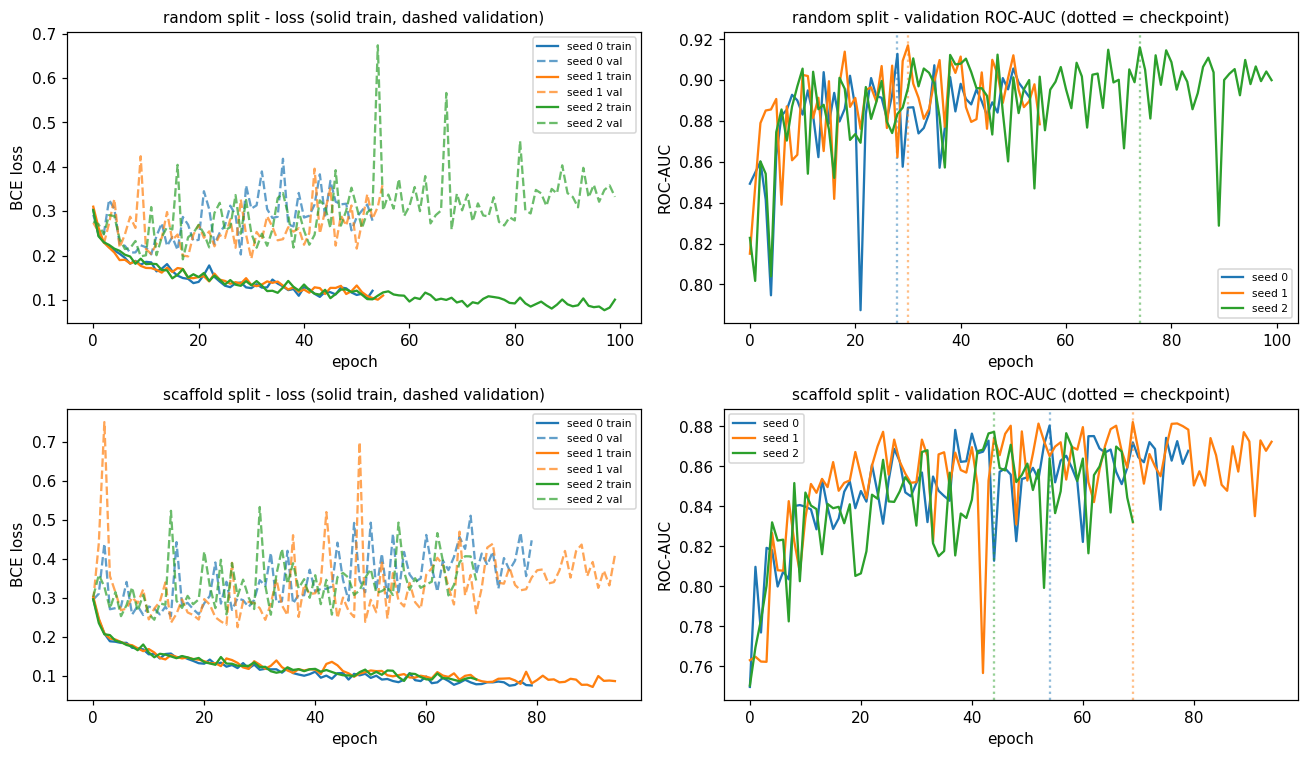

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
colors = {0: "#1f77b4", 1: "#ff7f0e", 2: "#2ca02c"}

for row, name in enumerate(splits):
    for seed in SEEDS:
        h = runs[(name, seed)]["history"]
        axes[row, 0].plot(h["epoch"], h["train_loss"], color=colors[seed], label=f"seed {seed} train")
        axes[row, 0].plot(h["epoch"], h["val_loss"], color=colors[seed], ls="--", alpha=0.7, label=f"seed {seed} val")
        axes[row, 1].plot(h["epoch"], h["val_auc"], color=colors[seed], label=f"seed {seed}")
        axes[row, 1].axvline(int(h["val_auc"].idxmax()), color=colors[seed], ls=":", alpha=0.5)
    axes[row, 0].set_title(f"{name} split - loss (solid train, dashed validation)", fontsize=10)
    axes[row, 1].set_title(f"{name} split - validation ROC-AUC (dotted = checkpoint)", fontsize=10)
    for ax in axes[row]:
        ax.set_xlabel("epoch")
        ax.legend(fontsize=7)
    axes[row, 0].set_ylabel("BCE loss")
    axes[row, 1].set_ylabel("ROC-AUC")
plt.tight_layout()
plt.show()

In [35]:
summary = pd.DataFrame([{"split": n, "seed": s, "val_auc": round(r["val_auc"], 4),
                         "best_epoch": int(r["history"]["val_auc"].idxmax()),
                         "epochs_run": len(r["history"]),
                         "final_train_loss": round(r["history"]["train_loss"].iloc[-1], 4)}
                        for (n, s), r in runs.items()])
print(summary.to_string(index=False))

agg = summary.groupby("split")["val_auc"].agg(["mean", "std", "min", "max"]).round(4)
print()
print(agg.to_string())

spread = summary.groupby("split")["val_auc"].apply(lambda s: s.max() - s.min())
gap = agg.loc["random", "mean"] - agg.loc["scaffold", "mean"]
print(f"\nseed spread within a split: random {spread['random']:.4f}, scaffold {spread['scaffold']:.4f}")
print(f"gap between split strategies: {gap:.4f}")
print(f"ratio of split effect to largest seed spread: {gap / spread.max():.1f}x")

   split  seed  val_auc  best_epoch  epochs_run  final_train_loss
  random     0   0.9130          28          54            0.1206
  random     1   0.9171          30          56            0.1099
  random     2   0.9162          74         100            0.1005
scaffold     0   0.8804          54          80            0.0768
scaffold     1   0.8822          69          95            0.0878
scaffold     2   0.8773          44          70            0.0923

            mean     std     min     max
split                                   
random    0.9154  0.0022  0.9130  0.9171
scaffold  0.8800  0.0025  0.8773  0.8822

seed spread within a split: random 0.0041, scaffold 0.0049
gap between split strategies: 0.0354
ratio of split effect to largest seed spread: 7.2x


## Part F

In [36]:
from sklearn.metrics import (average_precision_score, accuracy_score, f1_score,
                             confusion_matrix, precision_recall_curve)

def youden(y_true, prob):
    fpr, tpr, thr = roc_curve(y_true, prob)
    return float(thr[np.argmax(tpr - fpr)])

def metrics(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"roc_auc": roc_auc_score(y_true, prob), "pr_auc": average_precision_score(y_true, prob),
            "accuracy": accuracy_score(y_true, pred), "sensitivity": tp / (tp + fn),
            "specificity": tn / (tn + fp), "f1": f1_score(y_true, pred),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}

rows, curves = [], {}
for name, split in splits.items():
    yte = y_all[split["test"]]
    prob = baseline[name]["model"].predict_proba(fps[split["test"]])[:, 1]
    thr = baseline[name]["threshold"]
    rows.append({"model": "fingerprint+LR", "split": name, "seed": "-", "threshold": round(thr, 4),
                 **metrics(yte, prob, thr)})
    curves[("fingerprint+LR", name, 0)] = (yte, prob)

    for seed in SEEDS:
        model = runs[(name, seed)]["model"]
        pv, tv = predict(model, DataLoader([graphs[i] for i in split["val"]], batch_size=256))
        pt, tt = predict(model, DataLoader([graphs[i] for i in split["test"]], batch_size=256))
        thr = youden(tv, pv)
        rows.append({"model": "GINE GNN", "split": name, "seed": seed, "threshold": round(thr, 4),
                     **metrics(tt, pt, thr)})
        curves[("GINE GNN", name, seed)] = (tt, pt)

results = pd.DataFrame(rows)
print(results.drop(columns=["tn", "fp", "fn", "tp"]).round(4).to_string(index=False))

         model    split seed  threshold  roc_auc  pr_auc  accuracy  sensitivity  specificity     f1
fingerprint+LR   random    -     0.5336   0.8917  0.9550    0.8746       0.8978       0.8000 0.9161
      GINE GNN   random    0     0.3901   0.9030  0.9623    0.8475       0.8711       0.7714 0.8970
      GINE GNN   random    1     0.2298   0.9117  0.9682    0.8915       0.9378       0.7429 0.9295
      GINE GNN   random    2     0.6514   0.9199  0.9713    0.8373       0.8356       0.8429 0.8868
fingerprint+LR scaffold    -     0.6501   0.8757  0.9490    0.8209       0.8341       0.7808 0.8753
      GINE GNN scaffold    0     0.9429   0.9121  0.9649    0.7905       0.7713       0.8493 0.8473
      GINE GNN scaffold    1     0.4687   0.8621  0.9399    0.7973       0.8161       0.7397 0.8585
      GINE GNN scaffold    2     0.8322   0.8819  0.9591    0.7703       0.7489       0.8356 0.8308


In [37]:
METRICS = ["roc_auc", "pr_auc", "accuracy", "sensitivity", "specificity", "f1"]

rows = []
for (model, split), grp in results.groupby(["model", "split"], sort=False):
    row = {"model": model, "split": split, "runs": len(grp)}
    row["threshold"] = f"{grp['threshold'].mean():.3f}" + (f" ± {grp['threshold'].std():.3f}" if len(grp) > 1 else "")
    for m in METRICS:
        row[m] = f"{grp[m].mean():.3f}" + (f" ± {grp[m].std():.3f}" if len(grp) > 1 else "")
    rows.append(row)

comparison = pd.DataFrame(rows).sort_values(["split", "model"])
print(comparison.to_string(index=False))

for name, split in splits.items():
    yte = y_all[split["test"]]
    ones = np.ones_like(yte)
    print(f"majority-class reference ({name} test): accuracy {accuracy_score(yte, ones):.3f}, "
          f"f1 {f1_score(yte, ones):.3f}, sensitivity 1.000, specificity 0.000, roc_auc 0.500")

         model    split  runs     threshold       roc_auc        pr_auc      accuracy   sensitivity   specificity            f1
      GINE GNN   random     3 0.424 ± 0.213 0.912 ± 0.008 0.967 ± 0.005 0.859 ± 0.029 0.881 ± 0.052 0.786 ± 0.052 0.904 ± 0.022
fingerprint+LR   random     1         0.534         0.892         0.955         0.875         0.898         0.800         0.916
      GINE GNN scaffold     3 0.748 ± 0.248 0.885 ± 0.025 0.955 ± 0.013 0.786 ± 0.014 0.779 ± 0.034 0.808 ± 0.060 0.846 ± 0.014
fingerprint+LR scaffold     1         0.650         0.876         0.949         0.821         0.834         0.781         0.875
majority-class reference (random test): accuracy 0.763, f1 0.865, sensitivity 1.000, specificity 0.000, roc_auc 0.500
majority-class reference (scaffold test): accuracy 0.753, f1 0.859, sensitivity 1.000, specificity 0.000, roc_auc 0.500


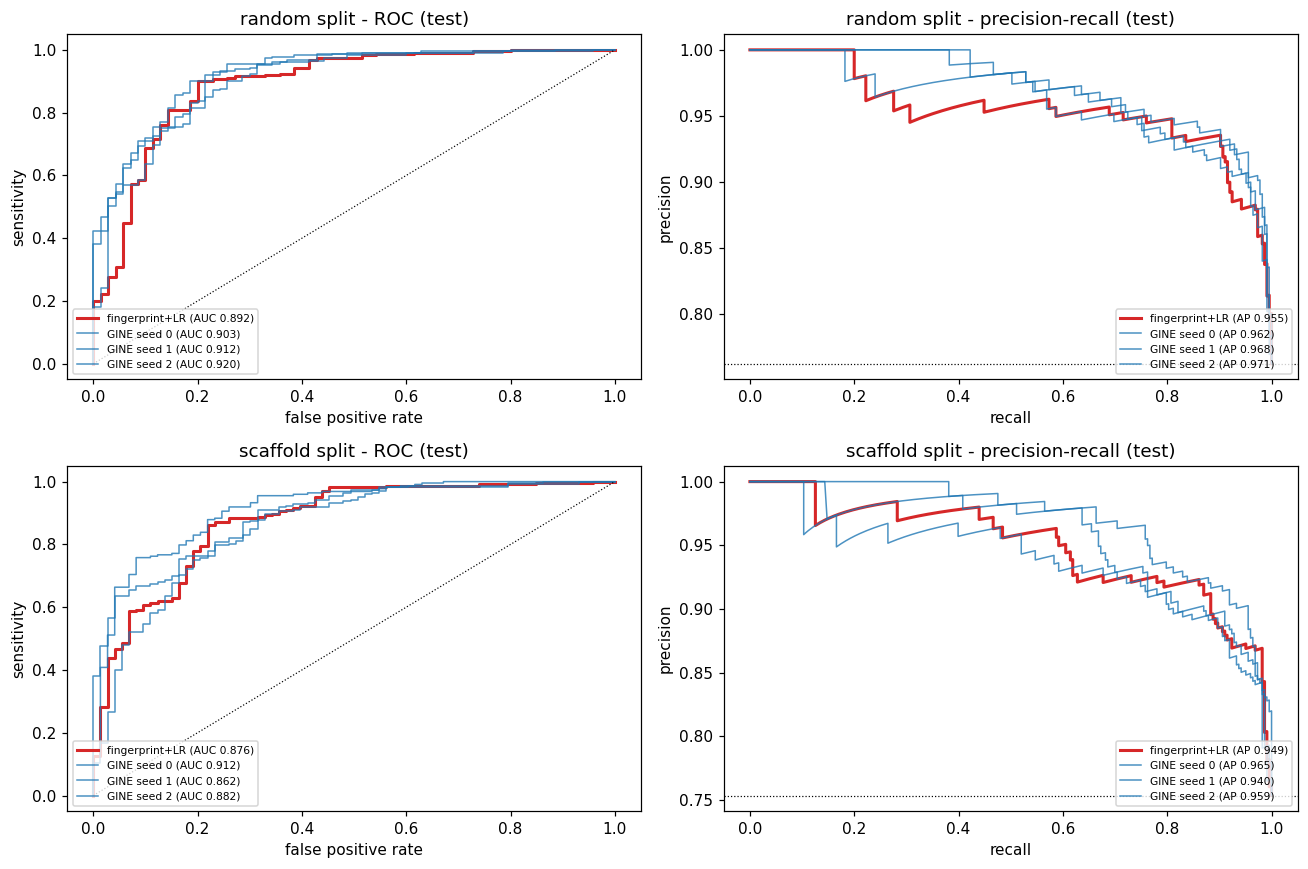

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, split in enumerate(splits):
    for (model, sp_name, seed), (yt, pr) in curves.items():
        if sp_name != split:
            continue
        fpr, tpr, _ = roc_curve(yt, pr)
        prec, rec, _ = precision_recall_curve(yt, pr)
        base = model == "fingerprint+LR"
        style = dict(color="#d62728", lw=2) if base else dict(color="#1f77b4", lw=1, alpha=0.8)
        label = model if base else f"GINE seed {seed}"
        axes[row, 0].plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(yt, pr):.3f})", **style)
        axes[row, 1].plot(rec, prec, label=f"{label} (AP {average_precision_score(yt, pr):.3f})", **style)
    axes[row, 0].plot([0, 1], [0, 1], "k:", lw=0.8)
    axes[row, 1].axhline(y_all[splits[split]["test"]].mean(), color="k", ls=":", lw=0.8)
    axes[row, 0].set(title=f"{split} split - ROC (test)", xlabel="false positive rate", ylabel="sensitivity")
    axes[row, 1].set(title=f"{split} split - precision-recall (test)", xlabel="recall", ylabel="precision")
    for ax in axes[row]:
        ax.legend(fontsize=7, loc="lower left" if ax is axes[row, 0] else "lower right")
plt.tight_layout()
plt.show()

representative GNN seed per split (median test ROC-AUC): {'random': 1, 'scaffold': 2}


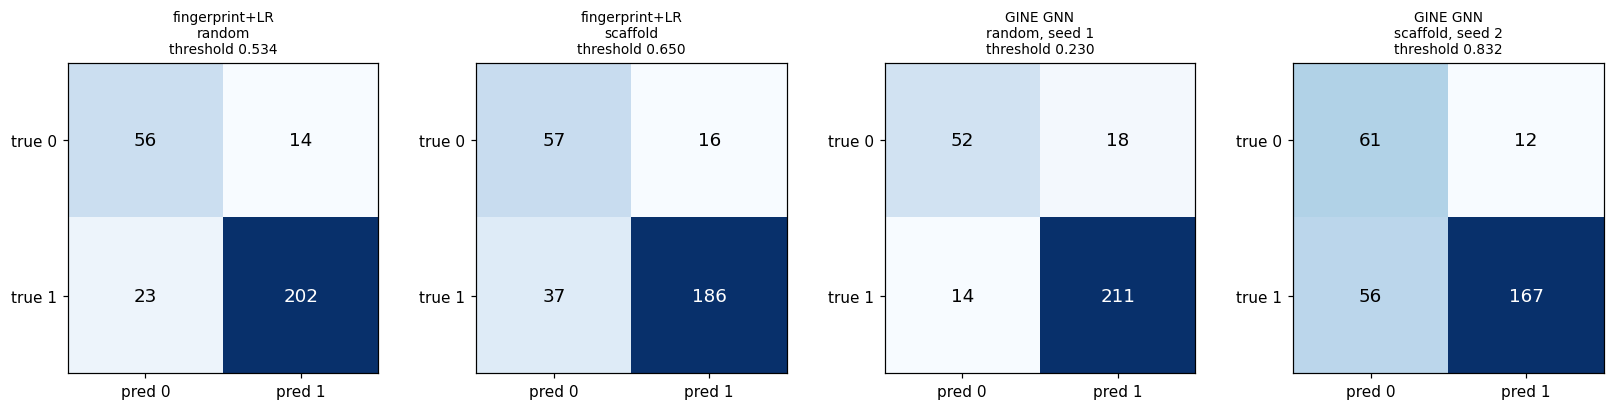

In [39]:
gnn = results[results["model"] == "GINE GNN"]
median_seed = {s: int(g.loc[(g["roc_auc"] - g["roc_auc"].median()).abs().idxmin(), "seed"])
               for s, g in gnn.groupby("split")}
print(f"representative GNN seed per split (median test ROC-AUC): {median_seed}")

panels = [("fingerprint+LR", s, None) for s in splits] + [("GINE GNN", s, median_seed[s]) for s in splits]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (model, split, seed) in zip(axes, panels):
    r = results[(results["model"] == model) & (results["split"] == split)]
    r = r if seed is None else r[r["seed"] == seed]
    cm = np.array([[r["tn"].iloc[0], r["fp"].iloc[0]], [r["fn"].iloc[0], r["tp"].iloc[0]]])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, int(v), ha="center", va="center",
                color="white" if v > cm.max() / 2 else "black", fontsize=12)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"],
           title=f"{model}\n{split}" + ("" if seed is None else f", seed {seed}") + f"\nthreshold {r['threshold'].iloc[0]:.3f}")
    ax.title.set_fontsize(9)
plt.tight_layout()
plt.show()

## Part G

In [40]:
split = splits["scaffold"]
seed = median_seed["scaffold"]
model = runs[("scaffold", seed)]["model"]

pv, tv = predict(model, DataLoader([graphs[i] for i in split["val"]], batch_size=256))
pt, _ = predict(model, DataLoader([graphs[i] for i in split["test"]], batch_size=256))
ptr, _ = predict(model, DataLoader([graphs[i] for i in split["train"]], batch_size=256))
threshold = youden(tv, pv)

test_df = data.loc[split["test"]].copy()
test_df["prob"] = pt
test_df["pred"] = (pt >= threshold).astype(int)
train_df = data.loc[split["train"]].copy()
train_df["prob"] = ptr
train_df["pred"] = (ptr >= threshold).astype(int)

false_pos = test_df[(test_df["y"] == 0) & (test_df["pred"] == 1)].nlargest(2, "prob")
false_neg = test_df[(test_df["y"] == 1) & (test_df["pred"] == 0)].nsmallest(2, "prob")
errors = pd.concat([false_pos, false_neg])
errors["type"] = ["false positive"] * len(false_pos) + ["false negative"] * len(false_neg)

print(f"GINE GNN, scaffold split, seed {seed}, frozen threshold {threshold:.4f}")
print(f"test errors: {int((test_df['y'] != test_df['pred']).sum())} of {len(test_df)} "
      f"({int(((test_df['y'] == 0) & (test_df['pred'] == 1)).sum())} false positives, "
      f"{int(((test_df['y'] == 1) & (test_df['pred'] == 0)).sum())} false negatives)")
print("\nmost confident errors:")
print(errors[["type", "y", "pred", "prob", "smiles"]].round(4).to_string(index=False))

GINE GNN, scaffold split, seed 2, frozen threshold 0.8322
test errors: 68 of 296 (12 false positives, 56 false negatives)

most confident errors:
          type   y  pred   prob                                                                    smiles
false positive 0.0     1 0.9944                                C[C@@H](CN1CC(=O)NC(=O)C1)N2CC(=O)NC(=O)C2
false positive 0.0     1 0.9891 CC(C)C1OC(=O)C2=CCCN2C(=O)c3coc(CC(=O)CC(O)\C=C(C)/C=C\CNC(=O)\C=C/C1C)n3
false negative 1.0     0 0.0050                                                           CC1OC(C)OC(O1)C
false negative 1.0     0 0.0050                                          C1=C2C(=CC=C1)C(C=C(O2)C(O)=O)=O


In [41]:
from rdkit import DataStructs

train_fps = [morgan.GetFingerprint(m) for m in train_df["mol"]]
neighbours = []
for pos, row in errors.iterrows():
    sims = np.array(DataStructs.BulkTanimotoSimilarity(morgan.GetFingerprint(row["mol"]), train_fps))
    j = int(sims.argmax())
    nb = train_df.iloc[j]
    neighbours.append({"type": row["type"], "error_smiles": row["smiles"], "error_y": int(row["y"]),
                       "error_prob": round(float(row["prob"]), 4), "tanimoto": round(float(sims[j]), 4),
                       "neighbour_smiles": nb["smiles"], "neighbour_y": int(nb["y"]),
                       "neighbour_prob": round(float(nb["prob"]), 4),
                       "mean_sim_to_train": round(float(sims.mean()), 4),
                       "neighbour_mol": nb["mol"], "error_mol": row["mol"]})

pairs = pd.DataFrame(neighbours)
print(pairs.drop(columns=["neighbour_mol", "error_mol"]).to_string(index=False))
print(f"\nmedian nearest-neighbour Tanimoto over the whole scaffold test set: "
      f"{np.median([max(DataStructs.BulkTanimotoSimilarity(morgan.GetFingerprint(m), train_fps)) for m in test_df['mol']]):.4f}")

          type                                                              error_smiles  error_y  error_prob  tanimoto                                                                   neighbour_smiles  neighbour_y  neighbour_prob  mean_sim_to_train
false positive                                C[C@@H](CN1CC(=O)NC(=O)C1)N2CC(=O)NC(=O)C2        0      0.9944    0.2941                                                            C(C1(CC(NC(C1)=O)=O)C)C            1          0.9995             0.0964
false positive CC(C)C1OC(=O)C2=CCCN2C(=O)c3coc(CC(=O)CC(O)\C=C(C)/C=C\CNC(=O)\C=C/C1C)n3        0      0.9891    0.2202 [C@@H]23[C@@H](CC[C@@H]1C[C@H](CC(O1)=O)O)[C@H](C=CC2=CCC[C@@H]3OC([C@H](CC)C)=O)C            1          0.9725             0.0883
false negative                                                           CC1OC(C)OC(O1)C        1      0.0050    0.2000                                                                           CC1CCCC1            1          1.0000             0.0

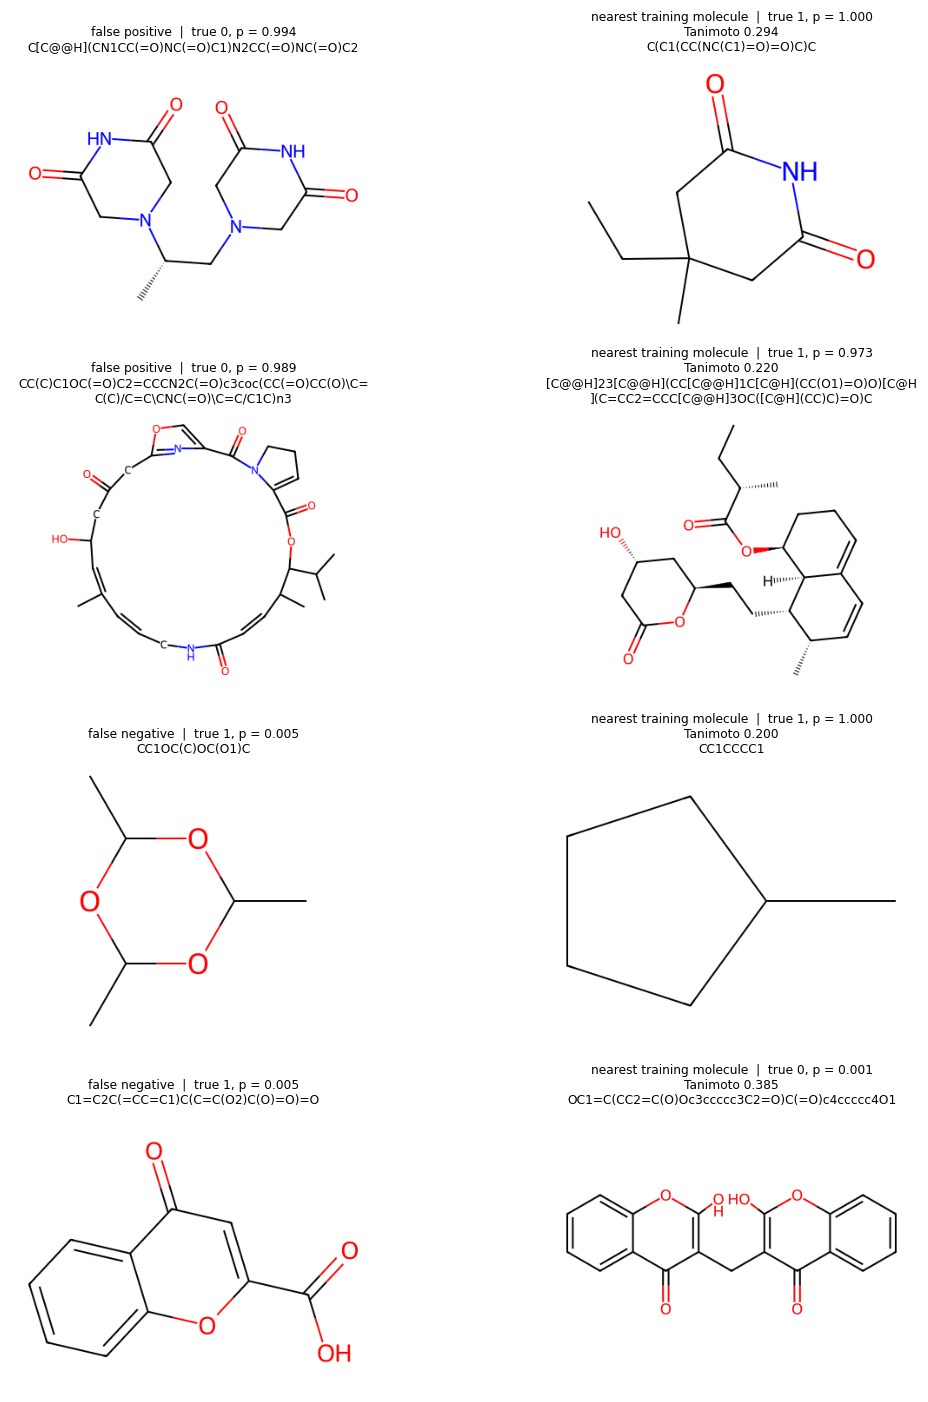

In [42]:
fig, axes = plt.subplots(len(pairs), 2, figsize=(11, 3.2 * len(pairs)))
for ax_row, (_, p) in zip(axes, pairs.iterrows()):
    ax_row[0].imshow(Draw.MolToImage(p["error_mol"], size=(420, 320)))
    ax_row[0].set_title(f"{p['type']}  |  true {p['error_y']}, p = {p['error_prob']:.3f}\n"
                        + "\n".join(textwrap.wrap(p["error_smiles"], 46)), fontsize=8)
    ax_row[1].imshow(Draw.MolToImage(p["neighbour_mol"], size=(420, 320)))
    ax_row[1].set_title(f"nearest training molecule  |  true {p['neighbour_y']}, p = {p['neighbour_prob']:.3f}\n"
                        f"Tanimoto {p['tanimoto']:.3f}\n"
                        + "\n".join(textwrap.wrap(p["neighbour_smiles"], 46)), fontsize=8)
    for ax in ax_row:
        ax.axis("off")
plt.tight_layout()
plt.show()